# Exploração dos dados

**Pergunta de negócio:** com capacidade limitada de revisão, quais transações revisar para maximizar o valor de fraude capturado?

**Regra desta análise (D5 em `docs/decisoes.md`):** estrutura e ausentes usam a base inteira. Tudo que envolve `isFraud` usa só os primeiros 60% no tempo, para não expor padrões do período de teste.

Cada bloco termina com as conclusões da análise.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import pyarrow.parquet as pq

# O notebook pode rodar a partir da raiz do projeto ou da pasta notebooks/.
RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
ARQUIVO = RAIZ / "data" / "processed" / "treino.parquet"

SEGUNDOS_POR_DIA = 86_400

## Bloco 1: estrutura

Objetivo: saber o que existe na base e se `TransactionDT` permite uma divisão temporal.

### 1.1 Colunas por grupo e tipo

Aqui só o esquema do arquivo é lido, sem carregar os dados na memória.

In [2]:
arquivo = pq.ParquetFile(ARQUIVO)
esquema = arquivo.schema_arrow
print(f"Linhas: {arquivo.metadata.num_rows:,} | Colunas: {len(esquema.names)}")


def grupo_da_coluna(nome: str) -> str:
    """Agrupa colunas numeradas pelo prefixo, como V1, V2 -> V."""
    encontrado = re.match(r"(V|C|D|M|card|addr|dist|id_)\d+$", nome)
    return encontrado.group(1) if encontrado else "outras"


colunas = pd.DataFrame(
    {
        "coluna": esquema.names,
        "tipo": [str(tipo).split("<")[0] for tipo in esquema.types],
    }
)
colunas["grupo"] = colunas["coluna"].map(grupo_da_coluna)

display(pd.crosstab(colunas["grupo"], colunas["tipo"], margins=True, margins_name="total"))
print("Colunas em 'outras':", ", ".join(colunas.loc[colunas["grupo"] == "outras", "coluna"]))

Linhas: 590,540 | Colunas: 434


tipo,dictionary,float,int16,int32,int8,total
grupo,,,,,,
C,0,14,0,0,0,14
D,0,15,0,0,0,15
M,9,0,0,0,0,9
V,0,339,0,0,0,339
addr,0,2,0,0,0,2
card,2,3,1,0,0,6
dist,0,2,0,0,0,2
id_,15,23,0,0,0,38
outras,5,1,0,2,1,9


Colunas em 'outras': TransactionID, isFraud, TransactionDT, TransactionAmt, ProductCD, P_emaildomain, R_emaildomain, DeviceType, DeviceInfo


### 1.2 Integridade da chave e do tempo

`TransactionDT` é um contador de segundos a partir de uma referência que o dataset não informa. Por isso, ele vira "dias desde a referência", e não uma data real.

In [3]:
base = pd.read_parquet(ARQUIVO, columns=["TransactionID", "TransactionDT"])

pd.Series(
    {
        "TransactionID duplicados": int(base["TransactionID"].duplicated().sum()),
        "TransactionDT nulos": int(base["TransactionDT"].isna().sum()),
        "Linhas já ordenadas no tempo": bool(base["TransactionDT"].is_monotonic_increasing),
        "Instantes repetidos em TransactionDT": int(base["TransactionDT"].duplicated().sum()),
        "Menor TransactionDT (s)": int(base["TransactionDT"].min()),
        "Maior TransactionDT (s)": int(base["TransactionDT"].max()),
        "Período coberto (dias)": round(
            (int(base["TransactionDT"].max()) - int(base["TransactionDT"].min())) / SEGUNDOS_POR_DIA, 1
        ),
    },
    name="valor",
).to_frame()

,valor
TransactionID duplicados,0
TransactionDT nulos,0
Linhas já ordenadas no tempo,True
Instantes repetidos em TransactionDT,17191
Menor TransactionDT (s),86400
Maior TransactionDT (s),15811131
Período coberto (dias),182.0


### 1.3 Como é uma linha

As cinco primeiras transações, em poucas colunas e sem `isFraud`.

In [ ]:
pd.read_parquet(
    ARQUIVO,
    columns=["TransactionID", "TransactionDT", "TransactionAmt", "ProductCD", "card4", "card6"],
).head()

### 1.4 Volume ao longo do tempo

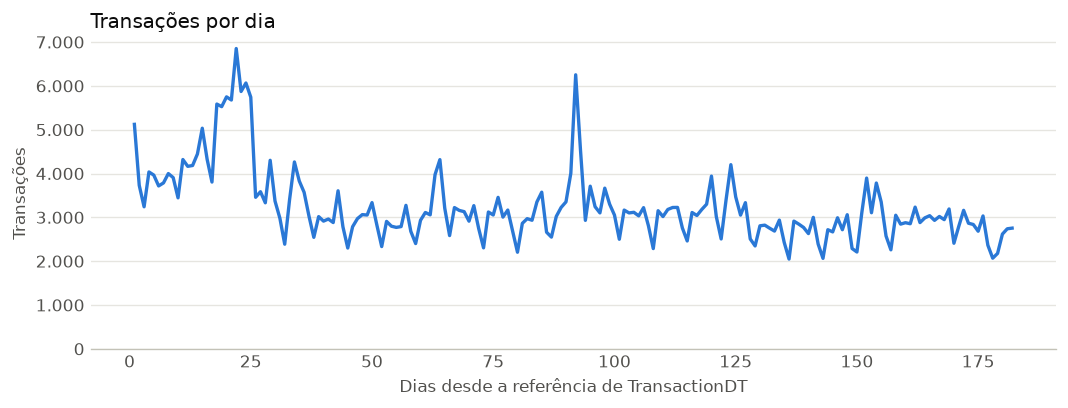

,valor
Dias no intervalo,182.0
Dias sem transação,0.0
Mínimo por dia,2048.0
Mediana por dia,3049.5
Máximo por dia,6852.0
Dia do máximo,22.0


In [5]:
dia = (base["TransactionDT"] // SEGUNDOS_POR_DIA).astype("int32")
todos_os_dias = range(dia.min(), dia.max() + 1)
por_dia = dia.value_counts().reindex(todos_os_dias, fill_value=0).sort_index()

fig, ax = plt.subplots(figsize=(9, 3.5), dpi=120)
ax.plot(por_dia.index, por_dia.to_numpy(), color="#2a78d6", linewidth=2)
ax.set_title("Transações por dia", loc="left", color="#0b0b0b")
ax.set_xlabel("Dias desde a referência de TransactionDT", color="#52514e")
ax.set_ylabel("Transações", color="#52514e")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: f"{int(valor):,}".replace(",", ".")))
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors="#52514e", length=0)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
fig.tight_layout()
plt.show()

pd.Series(
    {
        "Dias no intervalo": len(por_dia),
        "Dias sem transação": int((por_dia == 0).sum()),
        "Mínimo por dia": int(por_dia.min()),
        "Mediana por dia": float(por_dia.median()),
        "Máximo por dia": int(por_dia.max()),
        "Dia do máximo": int(por_dia.idxmax()),
    },
    name="valor",
).to_frame()

### Conclusões do Bloco 1

- A base tem 590.540 transações e 434 colunas, sem `TransactionID` duplicado e sem `TransactionDT` nulo. As linhas já estão em ordem de tempo, e o período cobre 182 dias sem nenhum dia vazio.
- O volume diário não é constante. A mediana é de 3.049,5 transações, com mínimo de 2.048 e máximo de 6.852 no dia 22. Os picos mais acentuados ainda não têm explicação.
- Como o volume varia, 60% das transações não equivalem a 60% dos dias. A divisão temporal precisa declarar qual dos dois usa.
- Há 17.191 transações no mesmo instante de outra anterior. Transações com o mesmo `TransactionDT` precisam ficar no mesmo período.
- Este bloco não usa `isFraud`, então o volume sozinho não mostra nenhum padrão de fraude.

## Bloco 2: fraude no tempo

Objetivo: verificar se a taxa de fraude é estável ao longo do tempo. Isso diz se a divisão temporal 60/20/20 faz sentido.

**Regra (D5):** neste bloco, usamos só os primeiros 60% das transações (por tempo), para não expor padrões do período de teste.

### 2.1 Corte de 60% e taxa geral

In [6]:
cutoff_dt = base["TransactionDT"].quantile(0.6)
print(f"Cutoff em TransactionDT: {cutoff_dt}")

# Recarregar com isFraud agora
base_fraud = pd.read_parquet(ARQUIVO, columns=["TransactionDT", "isFraud"])
base_60 = base_fraud[base_fraud["TransactionDT"] <= cutoff_dt]

print(f"\nPrimeiros 60% do tempo:")
print(f"  Transações: {len(base_60):,} de {len(base_fraud):,}")
print(f"  Fraudes: {base_60['isFraud'].sum():,} ({100 * base_60['isFraud'].mean():.2f}%)")
print(f"  Legítimas: {(base_60['isFraud'] == 0).sum():,}")

Cutoff em TransactionDT: 8745782.399999999

Primeiros 60% do tempo:
  Transações: 354,324 de 590,540
  Fraudes: 11,988 (3.38%)
  Legítimas: 342,336


### 2.2 Taxa de fraude por semana

In [7]:
# Semana = 7 dias
SEGUNDOS_POR_SEMANA = SEGUNDOS_POR_DIA * 7
semana = (base_60["TransactionDT"] // SEGUNDOS_POR_SEMANA).astype("int32")

# Agrupar por semana
taxa_semana = base_60.groupby(semana)["isFraud"].agg(["sum", "count", "mean"]).reset_index()
taxa_semana.columns = ["semana", "fraudes", "total", "taxa"]
taxa_semana["taxa_pct"] = 100 * taxa_semana["taxa"]

print("Taxa de fraude por semana:")
print(taxa_semana.to_string(index=False))
print(f"\nResumo:")
print(f"  Taxa mínima: {taxa_semana['taxa_pct'].min():.2f}%")
print(f"  Taxa máxima: {taxa_semana['taxa_pct'].max():.2f}%")
print(f"  Desvio padrão: {taxa_semana['taxa_pct'].std():.2f}%")
print(f"  Coeficiente de variação: {100 * taxa_semana['taxa_pct'].std() / taxa_semana['taxa_pct'].mean():.1f}%")

Taxa de fraude por semana:
 semana  fraudes  total     taxa  taxa_pct
      0      668  23810 0.028055  2.805544
      1      727  27803 0.026148  2.614826
      2      879  34470 0.025500  2.550044
      3      690  37251 0.018523  1.852299
      4      919  24041 0.038226  3.822636
      5      838  21868 0.038321  3.832083
      6      787  20392 0.038594  3.859357
      7      825  20025 0.041199  4.119850
      8      922  20246 0.045540  4.553986
      9     1014  23596 0.042973  4.297339
     10      900  20860 0.043145  4.314477
     11      685  19831 0.034542  3.454188
     12      848  21734 0.039017  3.901721
     13      935  27770 0.033669  3.366943
     14      351  10627 0.033029  3.302908

Resumo:
  Taxa mínima: 1.85%
  Taxa máxima: 4.55%
  Desvio padrão: 0.77%
  Coeficiente de variação: 21.9%


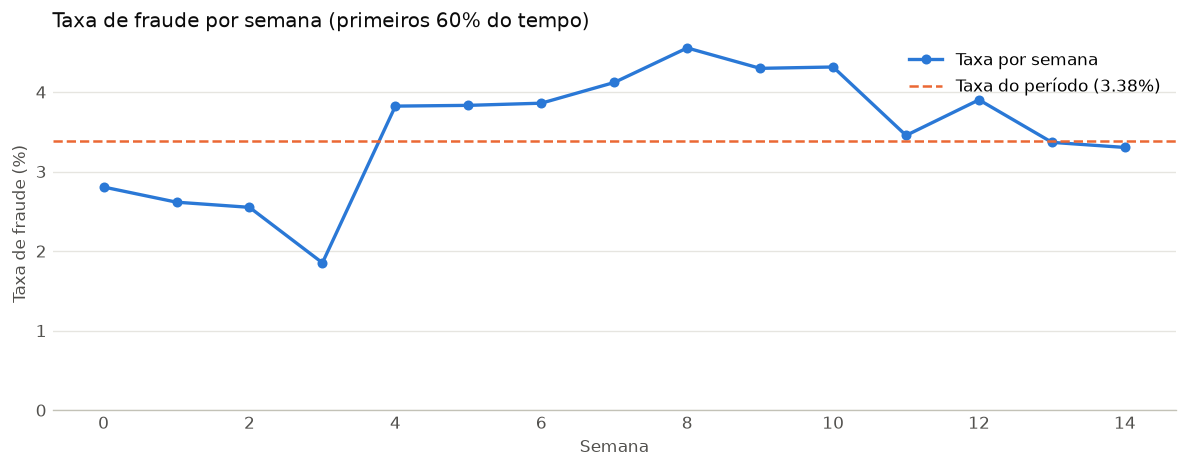

In [8]:
fig, ax = plt.subplots(figsize=(10, 4), dpi=120)

# Gráfico de linha
ax.plot(taxa_semana["semana"], taxa_semana["taxa_pct"], 
        marker="o", color="#2a78d6", linewidth=2, markersize=5, label="Taxa por semana")

# Linha da taxa real do período: fraudes / transações, sem peso igual por semana
taxa_periodo = 100 * base_60["isFraud"].mean()
ax.axhline(y=taxa_periodo, color="#eb6834", linestyle="--", linewidth=1.5, label=f"Taxa do período ({taxa_periodo:.2f}%)")

ax.set_title("Taxa de fraude por semana (primeiros 60% do tempo)", loc="left", color="#0b0b0b")
ax.set_xlabel("Semana", color="#52514e")
ax.set_ylabel("Taxa de fraude (%)", color="#52514e")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors="#52514e", length=0)
ax.legend(loc="upper right", frameon=False)

for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")

fig.tight_layout()
plt.show()

### Conclusões do Bloco 2

- Nos primeiros 60% das transações, há 11.988 fraudes em 354.324 transações, uma taxa de 3,38%.
- A taxa semanal vai de 1,85% (semana 3) a 4,55% (semana 8). As semanas 0 a 3 ficam entre 1,85% e 2,81%, e as semanas 4 a 14 entre 3,30% e 4,55%. Há um degrau entre as semanas 3 e 4, de 1,85% para 3,82%.
- A taxa muda com o tempo. Isso justifica a divisão temporal, e probabilidades ajustadas em um período podem errar em outro, o que afeta a calibração.
- A taxa agregada não explica por que uma transação é fraude nem a causa do degrau. Ela também não diz nada sobre os 40% finais, deixados de fora de propósito. As semanas 0 e 14 são parciais.

## Bloco 3: valor

Objetivo: entender como `TransactionAmt` se distribui em fraudes e legítimas, porque a pergunta de negócio é sobre valor capturado, não só quantidade de fraudes.

**Regra (D5):** este bloco usa só os primeiros 60% das transações no tempo.

Os valores abaixo são apresentados sem símbolo de moeda.

### 3.1 Distribuição do valor por classe

In [9]:
valores = pd.read_parquet(ARQUIVO, columns=["TransactionDT", "TransactionAmt", "isFraud"])
valores = valores[valores["TransactionDT"] <= cutoff_dt].drop(columns="TransactionDT")
# float64 evita acumular erro de arredondamento ao somar centenas de milhares de float32.
valores["TransactionAmt"] = valores["TransactionAmt"].astype("float64")

fraudes = valores.loc[valores["isFraud"] == 1, "TransactionAmt"]
legitimas = valores.loc[valores["isFraud"] == 0, "TransactionAmt"]

print(
    f"Transações: {len(valores):,} | "
    f"Valores nulos: {int(valores['TransactionAmt'].isna().sum())} | "
    f"Valores <= 0: {int((valores['TransactionAmt'] <= 0).sum())}"
)

percentis = [0.01, 0.25, 0.5, 0.75, 0.95, 0.99]
pd.DataFrame(
    {
        "Legítimas": legitimas.describe(percentiles=percentis),
        "Fraudes": fraudes.describe(percentiles=percentis),
    }
).round(2)

Transações: 354,324 | Valores nulos: 0 | Valores <= 0: 0


,Legítimas,Fraudes
count,342336.00,11988.00
mean,134.13,139.96
std,239.18,199.28
min,0.50,0.29
1%,10.00,7.23
25%,43.97,35.27
50%,69.61,77.00
75%,125.00,169.95
95%,437.95,450.00
99%,1100.13,994.00


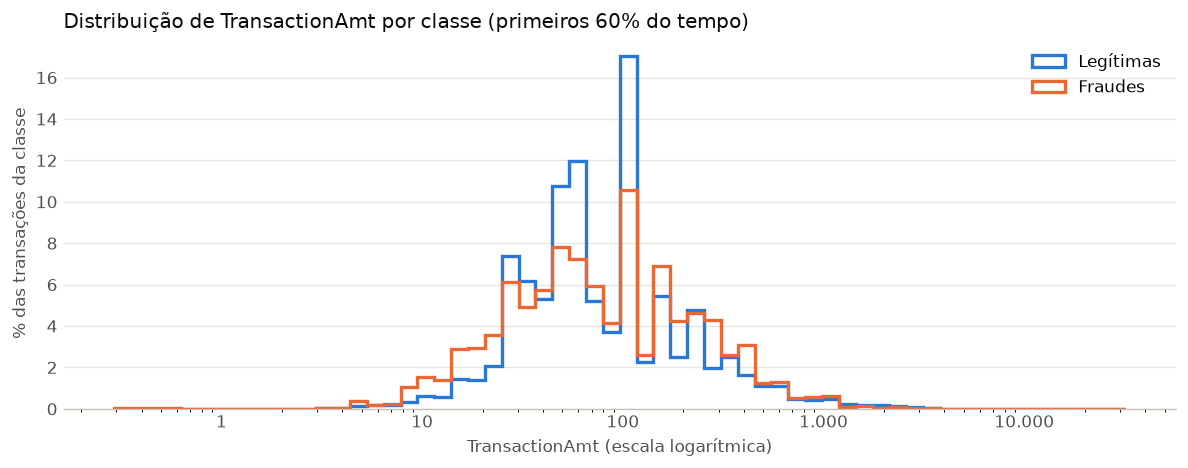

In [10]:
# Faixas iguais em escala log: o valor vai de centavos a dezenas de milhares.
faixas = np.logspace(np.log10(valores["TransactionAmt"].min()), np.log10(valores["TransactionAmt"].max()), 61)

fig, ax = plt.subplots(figsize=(10, 4), dpi=120)
# Cada classe soma 100%: compara o formato, apesar de haver muito mais legítimas.
for serie, nome, cor in [(legitimas, "Legítimas", "#2a78d6"), (fraudes, "Fraudes", "#eb6834")]:
    pesos = np.full(len(serie), 100 / len(serie))
    ax.hist(serie, bins=faixas, weights=pesos, histtype="step", linewidth=2, color=cor, label=nome)

ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: f"{valor:,.0f}".replace(",", ".") if valor >= 1 else f"{valor:.2f}".replace(".", ",")))
ax.set_title("Distribuição de TransactionAmt por classe (primeiros 60% do tempo)", loc="left", color="#0b0b0b")
ax.set_xlabel("TransactionAmt (escala logarítmica)", color="#52514e")
ax.set_ylabel("% das transações da classe", color="#52514e")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors="#52514e", length=0)
ax.legend(loc="upper right", frameon=False)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
fig.tight_layout()
plt.show()

### 3.2 Quanto do valor as fraudes concentram

A primeira tabela compara a participação das fraudes em quantidade e em valor. A segunda ordena as fraudes do maior para o menor valor e mostra quanto do valor fraudado fica em cada grupo.

In [11]:
por_classe = valores.groupby("isFraud")["TransactionAmt"].agg(["count", "sum", "mean"])
por_classe.index = por_classe.index.map({0: "Legítimas", 1: "Fraudes"})
por_classe.columns = ["Transações", "Valor total", "Valor médio"]
por_classe.insert(1, "% das transações", 100 * por_classe["Transações"] / por_classe["Transações"].sum())
por_classe.insert(3, "% do valor", 100 * por_classe["Valor total"] / por_classe["Valor total"].sum())
display(por_classe.round(2))

fraudes_ordenadas = fraudes.sort_values(ascending=False).to_numpy()
acumulado = fraudes_ordenadas.cumsum()
linhas = []
for fracao in [0.01, 0.05, 0.10, 0.20, 0.50]:
    quantidade = int(np.ceil(fracao * len(fraudes_ordenadas)))
    linhas.append(
        {
            "Maiores fraudes (%)": 100 * fracao,
            "Fraudes no grupo": quantidade,
            "Menor valor no grupo": fraudes_ordenadas[quantidade - 1],
            "% do valor fraudado": 100 * acumulado[quantidade - 1] / acumulado[-1],
        }
    )
pd.DataFrame(linhas).round(2)

,Transações,% das transações,Valor total,% do valor,Valor médio
isFraud,,,,,
Legítimas,342336,96.62,45916707.27,96.47,134.13
Fraudes,11988,3.38,1677790.68,3.53,139.96


,Maiores fraudes (%),Fraudes no grupo,Menor valor no grupo,% do valor fraudado
0,1.0,120,994.00,9.94
1,5.0,600,450.00,27.48
2,10.0,1199,311.95,41.18
3,20.0,2398,200.00,59.59
4,50.0,5994,77.00,86.63


### Conclusões do Bloco 3

- Em valor, fraudes e legítimas são parecidas. A mediana é 77,00 nas fraudes e 69,61 nas legítimas, e a média é 139,96 e 134,13. As fraudes são 3,38% das transações e 3,53% do valor.
- O valor fraudado é concentrado. As 20% maiores fraudes somam 59,59% do valor fraudado, e as 50% maiores somam 86,63%.
- O valor sozinho não separa fraude de compra legítima, e a chance de fraude sozinha ignora que as maiores fraudes pesam mais. A hipótese é priorizar combinando as duas coisas, a ser testada na Etapa 7.
- Estes números não mostram um fator determinístico de fraude. Eles também não mostram se dá para estimar bem a chance de fraude nem quanto custa cada revisão. A concentração de valor nas legítimas não foi medida, e o resultado vale só para os primeiros 60%.

## Bloco 4: valores ausentes

Objetivo: saber quanto falta em cada grupo de colunas, quantas transações têm dados de identidade e se isso muda ao longo do tempo.

**Regra (D5):** este bloco usa a base inteira e não envolve `isFraud`.

Uma "célula" é o cruzamento de uma linha com uma coluna. Se um grupo tem 10 colunas e 100 linhas, ele tem 1.000 células. "% ausente" é a parte dessas células que está vazia.

### 4.1 Ausentes por grupo de colunas

In [12]:
GRUPOS = ["C", "D", "M", "V", "id_"]
colunas_por_grupo = {g: colunas.loc[colunas["grupo"] == g, "coluna"].tolist() for g in GRUPOS}
colunas_dos_grupos = [c for g in GRUPOS for c in colunas_por_grupo[g]]

# Lê em lotes e guarda só as contagens, para não carregar 400 colunas na RAM de uma vez.
ausentes_por_coluna = pd.Series(0, index=colunas_dos_grupos, dtype="int64")
partes_semanais = []
for lote in arquivo.iter_batches(batch_size=50_000, columns=["TransactionDT", *colunas_dos_grupos]):
    tabela = lote.to_pandas()
    ausente = tabela[colunas_dos_grupos].isna()
    ausentes_por_coluna += ausente.sum()
    parte = pd.DataFrame({g: ausente[colunas_por_grupo[g]].sum(axis=1) for g in GRUPOS})
    parte["transacoes"] = 1
    parte["com_identidade"] = (~ausente[colunas_por_grupo["id_"]].all(axis=1)).astype("int8")
    partes_semanais.append(parte.groupby(tabela["TransactionDT"] // SEGUNDOS_POR_SEMANA).sum())
    del tabela, ausente

por_semana_ausentes = pd.concat(partes_semanais).groupby(level=0).sum()
total_linhas = arquivo.metadata.num_rows

pct_por_coluna = 100 * ausentes_por_coluna / total_linhas
pd.DataFrame(
    [
        {
            "Grupo": g.rstrip("_"),
            "Colunas": len(colunas_por_grupo[g]),
            "% ausente no grupo": pct_por_coluna[colunas_por_grupo[g]].mean(),
            "Menor % em uma coluna": pct_por_coluna[colunas_por_grupo[g]].min(),
            "Mediana % por coluna": pct_por_coluna[colunas_por_grupo[g]].median(),
            "Maior % em uma coluna": pct_por_coluna[colunas_por_grupo[g]].max(),
            "Colunas com mais de 90% ausente": int((pct_por_coluna[colunas_por_grupo[g]] > 90).sum()),
        }
        for g in GRUPOS
    ]
).set_index("Grupo").round(2)

,Colunas,% ausente no grupo,Menor % em uma coluna,Mediana % por coluna,Maior % em uma coluna,Colunas com mais de 90% ausente
Grupo,,,,,,
C,14,0.00,0.00,0.00,0.00,0
D,15,58.15,0.21,52.47,93.41,1
M,9,49.92,28.68,47.66,59.35,0
V,339,43.04,0.00,47.29,86.12,0
id,38,84.82,75.58,82.44,99.20,10


### 4.2 Cobertura da tabela de identidade

Uma transação conta como "com identidade" se ao menos uma coluna `id_` estiver preenchida.

In [13]:
com_identidade = int(por_semana_ausentes["com_identidade"].sum())
pd.Series(
    {
        "Transações": total_linhas,
        "Com identidade": com_identidade,
        "Sem identidade": total_linhas - com_identidade,
        "% com identidade": round(100 * com_identidade / total_linhas, 2),
    },
    name="valor",
).to_frame()

,valor
Transações,590540.00
Com identidade,144233.00
Sem identidade,446307.00
% com identidade,24.42


### 4.3 Ausentes ao longo do tempo

Cada painel é um grupo de colunas, todos na mesma escala de 0% a 100%. A primeira e a última semana são parciais.

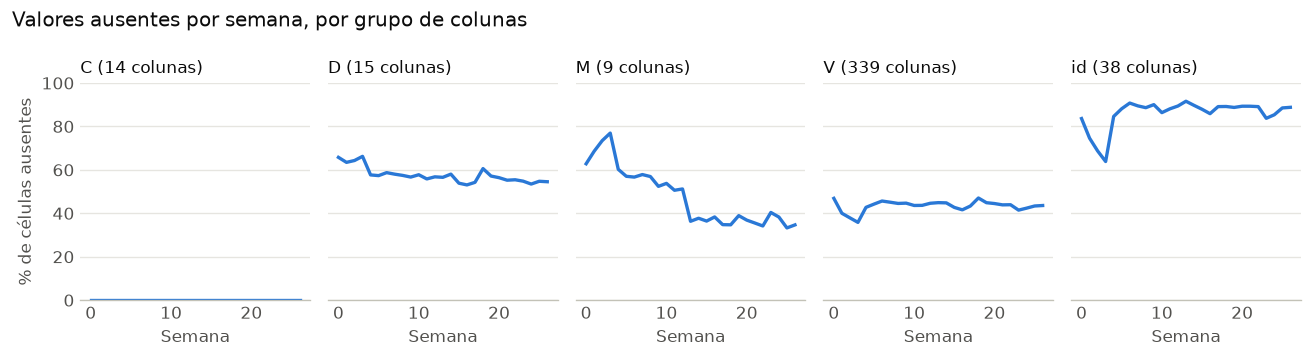

,C,D,M,V,id,% com identidade
semana,,,,,,
0,0.0,65.8,62.8,46.9,83.6,25.7
1,0.0,63.5,68.6,40.0,74.6,39.4
2,0.0,64.3,73.5,37.9,68.7,48.5
3,0.0,66.2,76.9,35.8,63.9,56.3
4,0.0,57.7,60.2,42.7,84.6,25.4
5,0.0,57.4,57.0,44.2,88.1,19.6
6,0.0,58.7,56.7,45.7,90.8,15.1
7,0.0,58.0,57.8,45.1,89.5,17.1
8,0.0,57.4,56.9,44.5,88.6,18.7


In [14]:
pct_semana = pd.DataFrame(
    {
        g: 100 * por_semana_ausentes[g] / (por_semana_ausentes["transacoes"] * len(colunas_por_grupo[g]))
        for g in GRUPOS
    }
)
pct_identidade_semana = 100 * por_semana_ausentes["com_identidade"] / por_semana_ausentes["transacoes"]

fig, eixos = plt.subplots(1, 5, figsize=(11, 3), dpi=120, sharey=True)
for ax, g in zip(eixos, GRUPOS):
    ax.plot(pct_semana.index, pct_semana[g], color="#2a78d6", linewidth=2)
    ax.set_title(f"{g.rstrip('_')} ({len(colunas_por_grupo[g])} colunas)", loc="left", color="#0b0b0b", fontsize=10)
    ax.set_xlabel("Semana", color="#52514e")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors="#52514e", length=0)
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
eixos[0].set_ylabel("% de células ausentes", color="#52514e")
fig.suptitle("Valores ausentes por semana, por grupo de colunas", x=0.01, ha="left", color="#0b0b0b")
fig.tight_layout()
plt.show()

resumo_tempo = pct_semana.rename(columns={"id_": "id"}).assign(**{"% com identidade": pct_identidade_semana})
resumo_tempo.index.name = "semana"
resumo_tempo.round(1)

### Conclusões do Bloco 4

- O grupo C não tem campos vazios. Os percentuais de ausentes são 43,04% em V, 49,92% em M, 58,15% em D e 84,82% em id. Só 24,42% das transações têm dados de identidade.
- Os ausentes mudam com o tempo. Em id, passam de 63,9% na semana 3 para 84,6% na semana 4. Em M, passam de 51,2% na semana 12 para 36,3% na semana 13.
- O salto de id acontece na mesma passagem em que a taxa de fraude sobe de 1,85% para 3,82%, e nas semanas 0 a 3 as duas séries caem juntas.
- Um modelo pode aprender a ausência de identidade como sinal de fraude, e esse sinal pode não se manter. A validação temporal serve para verificar isso.
- A coincidência é uma correlação e não prova causa. O motivo não foi investigado, e uma mudança na forma de registrar os dados poderia explicar as duas séries.

## Bloco 5: categorias e cartão

Objetivo: saber quantos valores diferentes existem em cada coluna de categoria, quantas transações existem por cartão e como a taxa de fraude muda entre categorias.

**Regra (D5):** as seções 5.1 e 5.2 descrevem a estrutura e usam a base inteira. A seção 5.3 envolve `isFraud` e usa só os primeiros 60% no tempo.

### 5.1 Número de categorias

In [15]:
COLUNAS_CARTAO = [f"card{i}" for i in range(1, 7)]
COLUNAS_CATEGORICAS = ["ProductCD", *COLUNAS_CARTAO, "P_emaildomain", "R_emaildomain"]
categoricas = pd.read_parquet(ARQUIVO, columns=COLUNAS_CATEGORICAS)

linhas = []
for coluna in COLUNAS_CATEGORICAS:
    serie = categoricas[coluna]
    contagem = serie.value_counts()
    linhas.append(
        {
            "Coluna": coluna,
            "Valores distintos": int(serie.nunique()),
            "% ausente": 100 * serie.isna().mean(),
            "Mais comum": contagem.index[0],
            "% da mais comum": 100 * contagem.iloc[0] / len(serie),
        }
    )
pd.DataFrame(linhas).set_index("Coluna").round(2)

,Valores distintos,% ausente,Mais comum,% da mais comum
Coluna,,,,
ProductCD,5,0.00,W,74.45
card1,13553,0.00,7919,2.53
card2,500,1.51,321.0,8.29
card3,114,0.27,150.0,88.27
card4,4,0.27,visa,65.16
card5,119,0.72,226.0,50.22
card6,4,0.27,debit,74.50
P_emaildomain,59,15.99,gmail.com,38.67
R_emaildomain,60,76.75,gmail.com,9.68


### 5.2 Transações por cartão

A base não informa um identificador de cartão. Por isso, comparamos duas aproximações: só `card1` e a combinação de `card1` a `card6`.

In [16]:
def resumo_por_cartao(contagem: pd.Series) -> dict:
    return {
        "Cartões aproximados": len(contagem),
        "Mediana de transações": float(contagem.median()),
        "Percentil 90": float(contagem.quantile(0.9)),
        "Máximo": int(contagem.max()),
        "% com só 1 transação": round(100 * float((contagem == 1).mean()), 2),
    }


por_card1 = categoricas["card1"].value_counts()
# dropna=False mantém as combinações em que algum campo do cartão está vazio.
por_combinacao = categoricas.groupby(COLUNAS_CARTAO, dropna=False, observed=True).size()

resumo_cartao = pd.DataFrame(
    {"Só card1": resumo_por_cartao(por_card1), "card1 a card6": resumo_por_cartao(por_combinacao)}
)
del categoricas
resumo_cartao

,Só card1,card1 a card6
Cartões aproximados,13553.00,14893.00
Mediana de transações,4.00,4.00
Percentil 90,46.00,41.00
Máximo,14932.00,14112.00
% com só 1 transação,25.41,27.55


### 5.3 Taxa de fraude por categoria

Só entram categorias com pelo menos 1.000 transações, porque taxas calculadas com poucas transações oscilam muito. Campos vazios aparecem como "(vazio)".

In [17]:
fraude_categorias = pd.read_parquet(
    ARQUIVO, columns=["TransactionDT", "isFraud", "ProductCD", "card4", "card6", "P_emaildomain"]
)
fraude_categorias = fraude_categorias[fraude_categorias["TransactionDT"] <= cutoff_dt]


def taxa_por_categoria(coluna: str, minimo: int = 1_000) -> pd.DataFrame:
    chave = fraude_categorias[coluna].astype("object").fillna("(vazio)")
    tabela = fraude_categorias.groupby(chave)["isFraud"].agg(["count", "sum"])
    tabela.columns = ["Transações", "Fraudes"]
    tabela["Taxa (%)"] = 100 * tabela["Fraudes"] / tabela["Transações"]
    return tabela[tabela["Transações"] >= minimo].sort_values("Taxa (%)", ascending=False).round(2)


taxa_produto = taxa_por_categoria("ProductCD")
display(taxa_produto)
display(taxa_por_categoria("card4"))
display(taxa_por_categoria("card6"))
display(taxa_por_categoria("P_emaildomain").head(10))

,Transações,Fraudes,Taxa (%)
ProductCD,,,
C,41081,4412,10.74
S,6314,379,6.00
H,26612,1133,4.26
R,28182,909,3.23
W,252135,5155,2.04


,Transações,Fraudes,Taxa (%)
card4,,,
discover,4180,258,6.17
mastercard,111634,3967,3.55
visa,231395,7563,3.27
american express,6288,175,2.78


,Transações,Fraudes,Taxa (%)
card6,,,
credit,95802,6015,6.28
debit,257663,5949,2.31


,Transações,Fraudes,Taxa (%)
P_emaildomain,,,
outlook.com,3008,255,8.48
hotmail.com,27824,1445,5.19
gmail.com,135247,5706,4.22
live.com,1887,67,3.55
(vazio),56600,1622,2.87
icloud.com,3626,103,2.84
anonymous.com,23195,556,2.40
yahoo.com,60021,1382,2.30
aol.com,17000,374,2.20


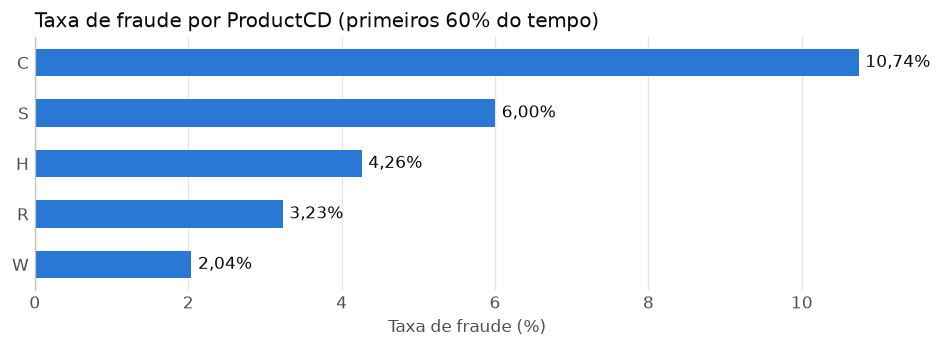

In [18]:
ordem = taxa_produto.sort_values("Taxa (%)")

fig, ax = plt.subplots(figsize=(8, 3), dpi=120)
barras = ax.barh(ordem.index.astype(str), ordem["Taxa (%)"], color="#2a78d6", height=0.55)
ax.bar_label(barras, labels=[f"{valor:.2f}%".replace(".", ",") for valor in ordem["Taxa (%)"]], padding=4, color="#0b0b0b")
ax.set_title("Taxa de fraude por ProductCD (primeiros 60% do tempo)", loc="left", color="#0b0b0b")
ax.set_xlabel("Taxa de fraude (%)", color="#52514e")
ax.set_xlim(left=0)
ax.margins(x=0.12)
ax.grid(axis="x", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors="#52514e", length=0)
for lado in ["top", "right", "bottom"]:
    ax.spines[lado].set_visible(False)
ax.spines["left"].set_color("#c3c2b7")
fig.tight_layout()
plt.show()

### Conclusões do Bloco 5

- A taxa de fraude muda bastante por produto. O produto C tem a maior taxa (10,74%) e o W, a menor (2,04%). Mesmo assim, W tem o maior número de fraudes (5.155, ou 43% do total), contra 4.412 (37%) em C.
- Taxa e quantidade respondem a perguntas diferentes: a taxa mostra onde cada revisão tem mais chance de achar fraude, e o total mostra onde está a maior parte das fraudes.
- O crédito tem taxa de 6,28% e o débito, de 2,31%.
- `card1` não identifica um cartão individual. São 13.553 valores, com mediana de 4 transações e máximo de 14.932 em 182 dias. A combinação de `card1` a `card6` ainda chega a 14.112 transações. Agregações "por cartão" feitas só com esses códigos misturariam clientes diferentes, o que precisa ser tratado na Etapa 4.
- As taxas valem só para os primeiros 60% e não incluem o valor das compras.